In [2]:
import sys
import tensorflow as tf

print("Python path:", sys.executable)
print("TensorFlow version:", tf.__version__)

Python path: c:\Users\srich\MindEase_CNN\backend\venv\Scripts\python.exe
TensorFlow version: 2.21.0


In [3]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import load_model
from tensorflow.keras.utils import plot_model
from PIL import Image

# Project root (notebook is inside backend/ml/notebooks)
PROJECT_ROOT = os.path.abspath("../../..")

MODEL_PATH = os.path.join(
    PROJECT_ROOT,
    "backend",
    "ml",
    "saved_models",
    "mindease_emotion_model_v3.keras"
)

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "outputs",
    "mindease_visuals"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASS_NAMES = ["angry", "happy", "neutral", "sad", "surprise"]

model = load_model(MODEL_PATH)

model.summary()

print("Model loaded successfully!")
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)
print("Output directory:", OUTPUT_DIR)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ emotion_output (Dense)          │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,298,641 (20.21 MB)

 Trainable params: 1,517,125 (5.79 MB)

 Non-trainable params: 747,264 (2.85 MB)

 Optimizer params: 3,034,252 (11.57 MB)

Model loaded successfully!
Model input: (None, 224, 224, 3)
Model output: (None, 5)
Output directory: c:\Users\srich\MindEase_CNN\outputs\mindease_visuals


In [4]:
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

architecture_path = os.path.join(
    OUTPUT_DIR,
    "cnn_v3_architecture.png"
)

plot_model(
    model,
    to_file=architecture_path,
    show_shapes=True,
    show_layer_names=True,
    expand_nested=True,
    dpi=150
)

display(Image(filename=architecture_path))

print("Architecture saved:", architecture_path)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\srich\\MindEase_CNN\\outputs\\mindease_visuals\\cnn_v3_architecture.png'

In [5]:
print("Architecture path:", architecture_path)
print("File exists:", os.path.exists(architecture_path))
print("Output directory exists:", os.path.exists(OUTPUT_DIR))

Architecture path: c:\Users\srich\MindEase_CNN\outputs\mindease_visuals\cnn_v3_architecture.png
File exists: False
Output directory exists: True


In [6]:
from tensorflow.keras.utils import plot_model

os.makedirs(OUTPUT_DIR, exist_ok=True)

plot_model(
    model,
    to_file=architecture_path,
    show_shapes=True,
    show_layer_names=True,
    expand_nested=True,
    dpi=150
)

print("Generated:", os.path.exists(architecture_path))

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.
Generated: False


In [7]:
from IPython.display import Image, display

if os.path.exists(architecture_path):
    display(Image(filename=architecture_path))
else:
    print("Architecture image was not generated.")

Architecture image was not generated.


In [8]:
print("History available:", "history" in globals())

if "history" in globals():
    print(history.history.keys())

History available: False


In [9]:
import os

TRAINING_DIR = os.path.join(
    PROJECT_ROOT, "backend", "ml", "training"
)

for root, dirs, files in os.walk(TRAINING_DIR):
    for file in files:
        print(os.path.join(root, file))

c:\Users\srich\MindEase_CNN\backend\ml\training\evaluate.py
c:\Users\srich\MindEase_CNN\backend\ml\training\train.py
c:\Users\srich\MindEase_CNN\backend\ml\training\train_v3.py


Found 6043 files belonging to 5 classes.


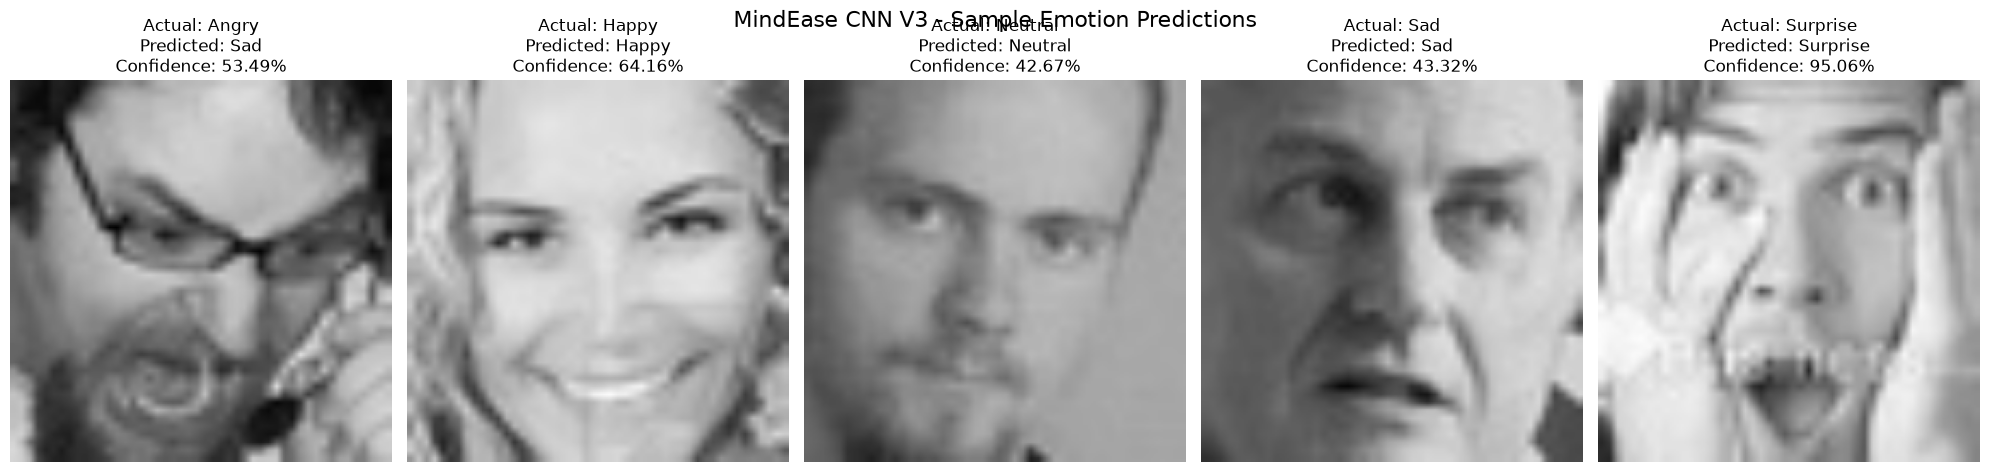

In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

TEST_DIR = os.path.join(
    PROJECT_ROOT, "backend", "ml", "dataset", "test"
)

CLASS_NAMES = ["angry", "happy", "neutral", "sad", "surprise"]

# Load test images in the exact training class order
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    class_names=CLASS_NAMES,
    image_size=(224, 224),
    batch_size=32,
    label_mode="categorical",
    shuffle=False
)

# Collect one image for each actual emotion class
sample_images = {}
sample_labels = {}

for images, labels in test_dataset:
    for image, label in zip(images.numpy(), labels.numpy()):
        actual_index = np.argmax(label)

        if actual_index not in sample_images:
            sample_images[actual_index] = image
            sample_labels[actual_index] = CLASS_NAMES[actual_index]

    if len(sample_images) == 5:
        break

# Load your trained model if not already loaded
model = tf.keras.models.load_model(MODEL_PATH)

# Display predictions
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for i, emotion in enumerate(CLASS_NAMES):

    image = sample_images[i]

    prediction = model.predict(
        np.expand_dims(image, axis=0),
        verbose=0
    )[0]

    predicted_index = np.argmax(prediction)
    predicted_emotion = CLASS_NAMES[predicted_index]
    confidence = prediction[predicted_index] * 100

    axes[i].imshow(image.astype("uint8"))
    axes[i].set_title(
        f"Actual: {emotion.title()}\n"
        f"Predicted: {predicted_emotion.title()}\n"
        f"Confidence: {confidence:.2f}%"
    )
    axes[i].axis("off")

plt.suptitle(
    "MindEase CNN V3 - Sample Emotion Predictions",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "five_emotion_predictions.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Found 6043 files belonging to 5 classes.
189/189 ━━━━━━━━━━━━━━━━━━━━ 80s 417ms/step


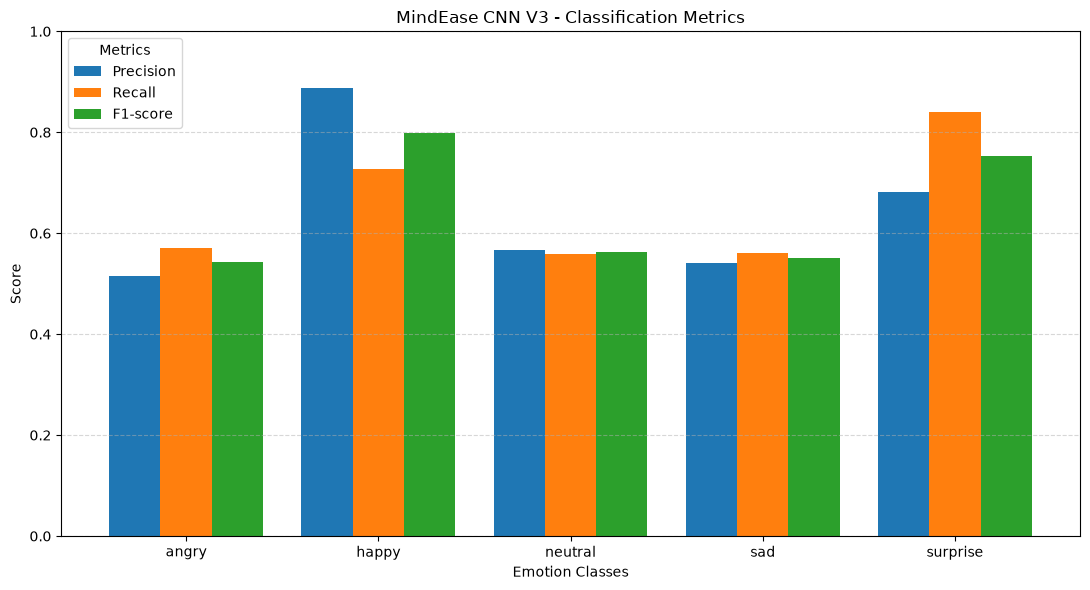

Graph saved at: c:\Users\srich\MindEase_CNN\outputs\mindease_visuals\classification_metrics_v3.png


,Precision,Recall,F1-score
angry,0.5160,0.5710,0.5421
happy,0.8884,0.7266,0.7994
neutral,0.5677,0.5580,0.5628
sad,0.5410,0.5613,0.5510
surprise,0.6813,0.8412,0.7528


In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import classification_report

# Dataset path
TEST_DIR = os.path.join(
    PROJECT_ROOT, "backend", "ml", "dataset", "test"
)

# Load test dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    class_names=CLASS_NAMES,
    image_size=(224, 224),
    batch_size=32,
    label_mode="categorical",
    shuffle=False
)

# Load trained CNN V3 model
model = tf.keras.models.load_model(MODEL_PATH, compile=False)

# Generate predictions
y_probabilities = model.predict(test_dataset, verbose=1)
y_pred = np.argmax(y_probabilities, axis=1)

# Get actual labels
y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for _, labels in test_dataset
])

# Generate classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

# Prepare metrics
metrics_df = pd.DataFrame({
    "Precision": [
        report[name]["precision"] for name in CLASS_NAMES
    ],
    "Recall": [
        report[name]["recall"] for name in CLASS_NAMES
    ],
    "F1-score": [
        report[name]["f1-score"] for name in CLASS_NAMES
    ]
}, index=CLASS_NAMES)

# Plot graph
ax = metrics_df.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("MindEase CNN V3 - Classification Metrics")
plt.xlabel("Emotion Classes")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Save graph
graph_path = os.path.join(
    OUTPUT_DIR,
    "classification_metrics_v3.png"
)

plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved at:", graph_path)

# Display exact metric values
display(metrics_df.round(4))